## 1. Divisão Inicial dos Dados (Train/Test Split)

A primeira etapa de um pipeline de processamento em ciência de dados consiste em separar o conjunto de dados em **dados de treino** e **dados de teste**. Essa etapa é fundamental para garantir que o modelo seja avaliado de forma justa, utilizando informações que não foram vistas durante o treinamento.


- **Split simples** (ex.: 80% treino / 20% teste) Adequado para a maioria dos cenários. Muitos dados (90%/10%). Poucos dados n < 100 (70%/30%).


A **estratificação** é uma técnica utilizada para garantir que a proporção das classes (em problemas de classificação) seja preservada tanto no conjunto de treino quanto no de teste.Evitrando modelos inviesados

Se o dataset possui **85% da classe A** e **15% da classe B**, a estratificação garante que:
- O conjunto de treino mantenha aproximadamente 85% / 15%.
- O conjunto de teste também mantenha essa proporção.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor


# Carregamento e Preparação dos Dados
from sklearn.datasets import fetch_openml

house_prices = fetch_openml(name="house_prices", as_frame=True)
df_original = house_prices.frame

# Selecionar features e o alvo
features_selecionadas = [
    'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea',
    'MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'FireplaceQu', 'Street'
]
alvo = 'SalePrice'
df = df_original[features_selecionadas + [alvo]].copy()

# Separar features (X) e alvo (y)
X = df.drop(alvo, axis=1)
y = df[alvo]

# Divisão em Treino e Teste
# A divisão é feita ANTES de qualquer `fit` ou `transform`.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#>>>>>>>> Identificação das Colunas por Tipo de Tratamento

# Features NUMERICAS que precisam de scaling e possivelmente imputação/transformação
# GarageCars e OverallQual são ordinais, mas podem ser tratadas como numéricas aqui
numeric_features = ['LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea']

# Feature CATEGORICAS ORDINAIS
# Note que o valor 'None' para ausência será tratado pelo imputer
ordinal_feature = ['FireplaceQu']
ordem_lareira = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']

# Features CATEGORICAS nominais para One-Hot Encoding
categorical_features = ['MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'Street']

# Features numéricas com assimetria a ser corrigida, mesmo estando nas numericas
skewed_features = ['LotArea', 'GrLivArea']

#>>>>>>>>Tratamento
# Pipeline para features com assimetria
# 1. Imputa a mediana (caso haja nulos)
# 2. Aplica a transformação Yeo-Johnson
# 3. Aplica o escalonamento padrão
skewed_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Pipeline para as demais features numéricas
# 1. Imputa a mediana
# 2. Aplica o escalonamento padrão
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline para a feature ordinal
# 1. Imputa a constante 'None' para valores ausentes
# 2. Aplica o OrdinalEncoder com a ordem especificada
ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('ordinal', OrdinalEncoder(categories=[ordem_lareira]))
])

# Pipeline para features categóricas nominais
# 1. Imputa o valor mais frequente (uma estratégia segura para estas colunas)
# 2. Aplica o OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')) # Ignora categorias novas no teste
])


# >>>>>Criação do ColumnTransformer para Unir os Pipelines
# O ColumnTransformer aplica os transformadores corretos às colunas corretas.
# Note que separamos as numéricas com e sem correção de assimetria.
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skewed_transformer, skewed_features),
        ('num', numeric_transformer, list(set(numeric_features) - set(skewed_features))), # Numéricas não assimétricas
        ('ord', ordinal_transformer, ordinal_feature),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Mantém colunas não especificadas (se houver)
)

# >>>>>> Criação do Pipeline Final com o Modelo
# O fluxo é: 1) Pré-processar os dados com o ColumnTransformer, 2) Treinar o modelo.
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=2025))
])


# >>>>>> Treinamento e Avaliação

# Ao chamar .fit(), o pipeline executa o .fit_transform() do pré-processador APENAS em X_train.
# Os parâmetros (medianas, lambdas, médias, desvios-padrão, categorias) são aprendidos SOMENTE com os dados de treino.
model_pipeline.fit(X_train, y_train)

# Ao chamar .score() ou .predict(), o pipeline aplica APENAS o .transform() em X_test,
# usando os parâmetros já aprendidos, evitando assim o vazamento de dados.
score = model_pipeline.score(X_test, y_test)
#print(model_pipeline.named_steps['regressor'].get_params())

print(f"Score R² do modelo no conjunto de teste: {score:.4f}")

# Exemplo de predição em um novo dado
# O pipeline cuida de todo o pré-processamento automaticamente
new_data = X_test.head(1)
prediction = model_pipeline.predict(new_data)
print(f"\nExemplo de Predição para o primeiro dado do teste: ${prediction[0]:,.2f}, valor real:$ {y_test.iloc[0]:,.2f}")

Score R² do modelo no conjunto de teste: 0.8802

Exemplo de Predição para o primeiro dado do teste: $138,137.00, valor real:$ 154,500.00


##2.  Tuning dos Hiperparâmetros do Modelo

Existem dois tipos de parâmetros.
- **Parâmetros do modelo**: aprendidos pelo modelo no ato de treinamento (por exemplo, pesos em Redes Neurais ou coeficientes em Regressão Linear).
- **hiperparâmetros**: que são aqueles que podem ser arbitrariamente inseridos pelo (por exemplo, o número de decision trees de uma Random Forest).

Após configurar todo o pipeline de pré-processamento, o próximo passo é ajustar os hiperparâmetros do modelo de Machine Learning (rodamos ja o modelo em deafult para comparação).  

O objetivo do *tuning* é encontrar a combinação de hiperparâmetros que produz o melhor desempenho no conjunto de validação.


Modelos como Random Forest (outros modelos tambem) possuem diversos hiperparâmetros que influenciam diretamente:

- a complexidade do modelo  
- a capacidade de generalização  
- o risco de overfitting  
- o tempo de treinamento  

Ajustar esses valores evita treinar modelos fracos ou modelos que se ajustam demais ao treino (Overfiting).


### Método utilizado: GridSearchCV

![texto do link](https://miro.medium.com/v2/resize:fit:640/format:webp/1*Je_xZzHl49PjQGQbQmjHHQ.jpeg)

Para realizar o tuning, utilizamos o **GridSearchCV**, que:

1. Monta uma grade de combinações de hiperparâmetros.  
2. Treina o pipeline completo (pré-processamento + modelo) para cada combinação.  
3. Avalia com validação cruzada (k-fold).  
4. Retorna a melhor configuração encontrada.

O uso do pipeline garante que:

- o pré-processamento é recalculado **somente** com dados do treino em cada fold  
- não ocorre nenhum tipo de vazamento de informação  
- a busca de hiperparâmetros é totalmente integrada ao fluxo

###Cross-Validation (CV) k-fold
A validação cruzada k-fold é uma técnica utilizada para avaliar o desempenho de um modelo de maneira mais confiável e estável.
Em vez de usar apenas uma divisão treino/teste, o conjunto de Treino dps dados é dividido em k partes (folds) de tamanhos semelhantes.

1. O conjunto de dados é dividido em **k folds**.
2. O modelo é treinado **k vezes**:
   - Em cada repetição, **k - 1 folds** são usados para treino.
   - O fold restante é usado como **validação**.
3. Cada fold é utilizado uma vez como validação.
4. O desempenho final é a **média** das k avaliações.



| Iteração | Treino                           | Validação |
|---------|-----------------------------------|-----------|
| 1       | F2, F3, F4, F5                    | F1        |
| 2       | F1, F3, F4, F5                    | F2        |
| 3       | F1, F2, F4, F5                    | F3        |
| 4       | F1, F2, F3, F5                    | F4        |
| 5       | F1, F2, F3, F4                    | F5        |

O modelo nunca é avaliado nos dados que usou para treinar, garantindo uma avaliação mais justa. k = 5 mais rapido, carater investigativo, usar k=10 para ajustes finais (mais lento, mas robusto)

Existem outros metodos de CV porem o mais usual é o k-fold

### Hiperparâmetros ajustados

Os hiperparâmetros do Random Forest considerados na grade foram:

- `n_estimators`: número de árvores na floresta  
- `max_depth`: profundidade máxima das árvores  
- `min_samples_split`: número mínimo de amostras para dividir um nó  
- `min_samples_leaf`: número mínimo de amostras em uma folha

Esses parâmetros controlam tanto a flexibilidade das árvores quanto o risco de overfitting.




In [ ]:
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=2025))
])

# >> Tuning dos hiperparâmetros do Random Forest

# Grade simples de hiperparâmetros (pode expandir se quiser)
param_grid = {
    'regressor__n_estimators': [200, 400],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_split': [2, 5],
    'regressor__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring='r2'# oque vou usar para definir os melhores hiperparametros
)

# >>>>>>>>>>>>>>>>> LISTAS DE CV's USUAIS

# estratificado para classificações
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# repete diferentew combinações do CV, é bem robusto, mas lento
from sklearn.model_selection import RepeatedKFold
cv = RepeatedKFold(n_splits=5, n_repeats=3)

# para series temporais
from sklearn.model_selection import TimeSeriesSplit
cv = TimeSeriesSplit(n_splits=5)
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>
##### Metricas Regressões
#'neg_mean_squared_error'
#'neg_root_mean_squared_error'
#'neg_mean_absolute_error'
#'neg_mape'
#'r2' (padrão mais comum)

####Classificação
#'accuracy'
#'precision'
#'recall'
#'f1'
#'roc_auc'


grid_search.fit(X_train, y_train)

print("Melhores hiperparâmetros encontrados:")
print(grid_search.best_params_)#

score = grid_search.score(X_test, y_test)
print(f"\nScore R² no conjunto de teste após tuning: {score:.4f}")

melhor_modelo = grid_search.best_estimator_ # selecionamos o melhor modelo


# Predição de exemplo
new_data = X_test.head(1)
prediction = grid_search.predict(new_data)
print(f"\nPredição: ${prediction[0]:,.2f}")
print(f"Valor real: ${y_test.iloc[0]:,.2f}")


Melhores hiperparâmetros encontrados:
{'regressor__max_depth': None, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 400}

Score R² no conjunto de teste após tuning: 0.8723

Predição: $137,642.43
Valor real: $154,500.00


Mas alem de ajustar os hiperparaâmetros podemos automatizar a escolha de melhores modelos, para isso:

In [ ]:
# Modelos e grids de hiperparâmetros
modelos = {
    "Regressão Linear": {
        "modelo": LinearRegression(),
        "param_grid": {
        }
    },
    "Random Forest": {
        "modelo": RandomForestRegressor(random_state=2025),
        "param_grid": {
            "regressor__n_estimators": [100, 300],
            "regressor__max_depth": [None, 10, 20],
            "regressor__min_samples_split": [2, 5]
        }
    },
    "KNN": {
        "modelo": KNeighborsRegressor(),
        "param_grid": {
            "regressor__n_neighbors": [3, 5, 7, 9],
            "regressor__weights": ["uniform", "distance"],
            "regressor__p": [1, 2]  # Manhattan ou Euclidiana
        }
    }
}

resultados = []
melhores_modelos = {}

# Loop para cada modelo + seu GridSearch
for nome, info in modelos.items():

    print(f"Treinando e ajustando: {nome} ...")

    modelo = info["modelo"]
    grid = info["param_grid"]

    # Monta o pipeline
    model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', modelo)
])

    # Grid search
    grid_search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    # Salva resultados
    melhores_modelos[nome] = grid_search.best_estimator_
    resultados.append({
        "Modelo": nome,
        "Melhor R2": grid_search.best_score_
    })

# Exibe tabela comparativa
df_resultados = pd.DataFrame(resultados).sort_values(by="Melhor R2", ascending=False)
df_resultados

Treinando e ajustando: Regressão Linear ...
Treinando e ajustando: Random Forest ...
Treinando e ajustando: KNN ...


,Modelo,Melhor R2
1,Random Forest,0.833327
2,KNN,0.808039
0,Regressão Linear,0.794690


Vamos ver o r² no grupo de teste, caso esse r² for maior que 0.05 podemos ter um overffiting. mas lembrando pode ser mera casualide do split inicial ser ruim.

In [ ]:

score = melhores_modelos['Random Forest'].score(X_test, y_test)
print(f"\nScore R² no conjunto de teste após tuning: {score:.4f}")
# Predição de exemplo
new_data = X_test.head(1)
prediction = melhores_modelos['Random Forest'].predict(new_data)
print(f"\nPredição: ${prediction[0]:,.2f}")
print(f"Valor real: ${y_test.iloc[0]:,.2f}")


Score R² no conjunto de teste após tuning: 0.8806

Predição: $138,224.42
Valor real: $154,500.00


Para determinar de maneira mais eficiente os hiperparametros temos algumas opções:

O **HalvingRandomSearchCV** é o melhor sucessor do RandomizedSearchCV quando você quer tunar hiperparâmetros de forma rápida e eficiente, especialmente em datasets médios/grandes.
Ele foi criado pelos próprios desenvolvedores do scikit-learn. Hoje é o método mais recomendado quando você não quer pagar o custo alto do Optuna (veremos na sequencia) , mas ainda quer algo muito melhor que o GridSearchCV tradicional.

### 3.4. Otimização de Hiperparâmetros com HalvingRandomSearchCV

A seleção dos hiperparâmetros foi realizada por meio do algoritmo **Successive Halving** implementado no `HalvingRandomSearchCV` do scikit-learn (versão ≥ 0.24). Esse método combina amostragem aleatória com eliminação progressiva de configurações pouco promissoras, sendo significativamente mais eficiente que o `GridSearchCV` e o `RandomizedSearchCV` tradicional.

O procedimento segue as seguintes etapas iterativas:

1. **Definição do espaço de busca**  
   Foi especificado um conjunto amplo de distribuições para os principais hiperparâmetros do modelo (ex.: número de árvores, profundidade máxima, taxa de aprendizado, regularizações L1/L2, etc.), utilizando as classes `scipy.stats.randint` e `scipy.stats.uniform`.

2. **Amostragem inicial de candidatos**  
   Um número inicial elevado de combinações de hiperparâmetros (`n_candidates`) é sorteado aleatoriamente do espaço definido.

3. **Primeira rodada (exploração rasa)**  
   Todos os candidatos são avaliados utilizando apenas uma fração pequena do conjunto de treinamento (aproximadamente 10%) e validação cruzada de 5-fold. Essa etapa é extremamente rápida.

4. **Eliminação sucessiva (successive halving)**  
   A cada iteração:
   - Apenas os melhores (1/factor) candidatos avançam (factor = 3 por padrão).
   - A quantidade de dados usados para treinamento é multiplicada por `factor`.
   - Os candidatos sobreviventes são reavaliados com mais recursos (mais dados e/ou mais folds).

5. **Rodadas finais (exploração intensiva)**  
   Nas últimas iterações, apenas os candidatos mais promissores são treinados com 100% dos dados de treinamento, garantando uma avaliação precisa do desempenho real.

6. **Seleção do modelo final**  
   O conjunto de hiperparâmetros que apresentou o maior score médio na validação cruzada (R² no caso de regressão) é selecionado como o melhor.

Esse processo permite explorar um espaço de busca muito maior do que o `GridSearchCV` com uma fração do custo computacional, mantendo ou até superando a qualidade da solução encontrada. Estudos recentes (Jamieson & Talwalkar, 2016; Li et al., 2018) demonstram que o Successive Halving obtém resultados próximos ao ótimo com apenas 20–40% do tempo exigido por buscas aleatórias tradicionais.





Otimização via HalvingRandomSearchCV: Random Forest


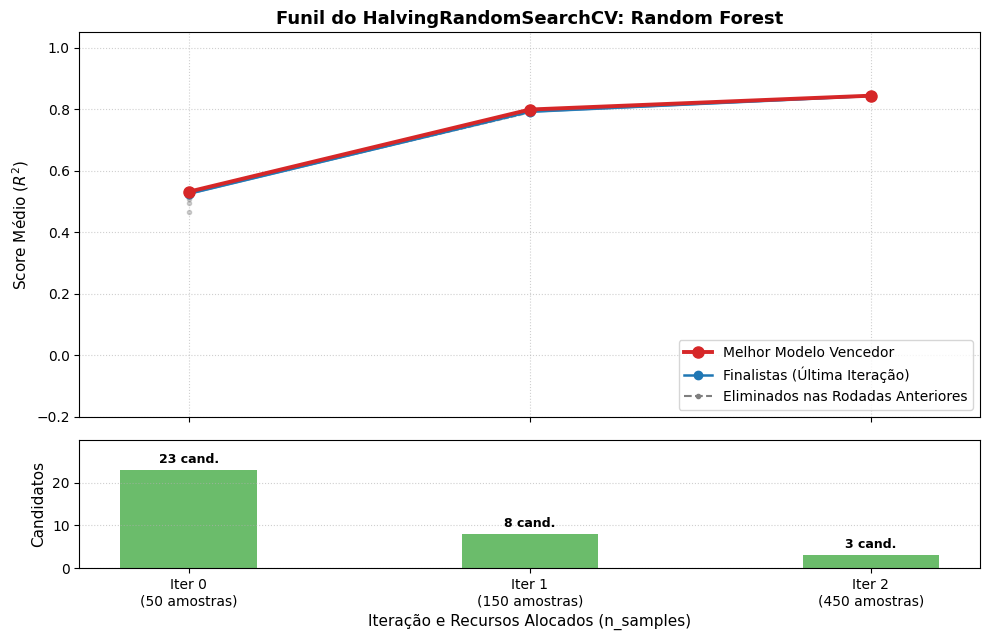

Otimização via HalvingRandomSearchCV: KNN


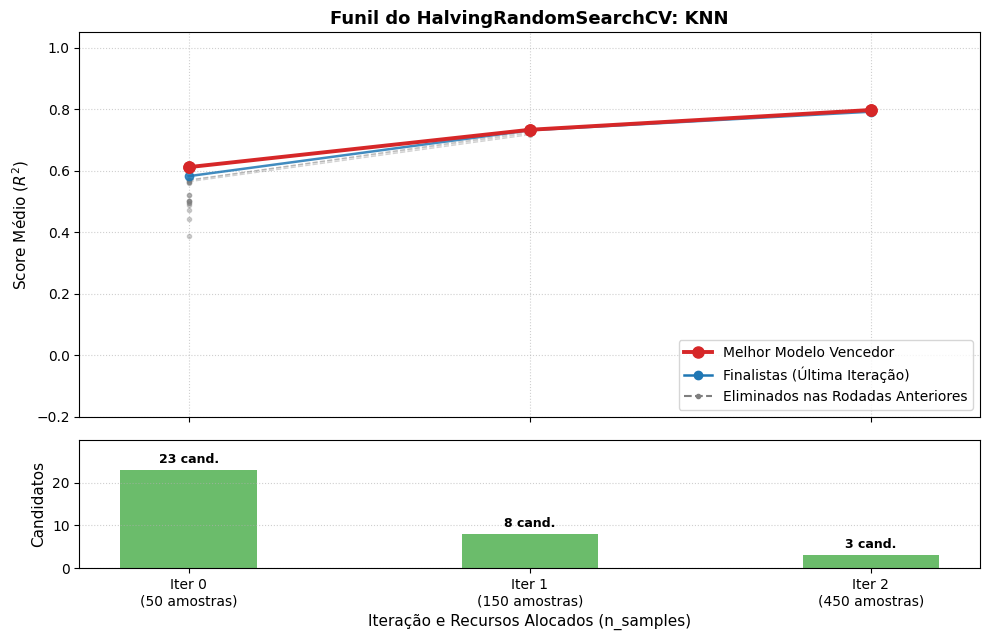

,Modelo,Melhor R2 (CV),Melhores Params
0,Random Forest,0.844020,"{'regressor__max_depth': 13, 'regressor__min_s..."
1,KNN,0.797415,"{'regressor__n_neighbors': 4, 'regressor__p': ..."


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from scipy.stats import randint

# 1. Definição da função de plotagem
def plotar_funil_halving(search, nome_modelo):
    df_cv = pd.DataFrame(search.cv_results_)
    df_cv['candidato_id'] = df_cv['params'].astype(str)

    # Filtra eventuais NaNs caso ocorram na primeira iteração
    df_valido = df_cv.dropna(subset=['mean_test_score'])
    if df_valido.empty:
        print(f"Aviso: Todos os scores de {nome_modelo} resultaram em NaN.")
        return

    ultima_iter = df_valido['iter'].max()
    df_ultima = df_valido[df_valido['iter'] == ultima_iter]
    finalistas = set(df_ultima['candidato_id'])
    melhor_id = df_ultima.loc[df_ultima['mean_test_score'].idxmax(), 'candidato_id']

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 6.5), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    # Painel 1: Evolução do R² por candidato
    for cand_id, grupo in df_cv.groupby('candidato_id'):
        grupo = grupo.sort_values('iter')
        if cand_id == melhor_id:
            ax1.plot(
                grupo['iter'], grupo['mean_test_score'],
                marker='o', color='#d62728', linewidth=2.8, markersize=8,
                zorder=4, label='Melhor Modelo Vencedor'
            )
        elif cand_id in finalistas:
            ax1.plot(
                grupo['iter'], grupo['mean_test_score'],
                marker='o', color='#1f77b4', linewidth=1.8, alpha=0.85, zorder=3
            )
        else:
            ax1.plot(
                grupo['iter'], grupo['mean_test_score'],
                marker='.', color='#7f7f7f', linewidth=1.0, linestyle='--', alpha=0.35, zorder=2
            )

    ax1.plot([], [], color='#1f77b4', marker='o', linewidth=1.8, label='Finalistas (Última Iteração)')
    ax1.plot([], [], color='#7f7f7f', linestyle='--', marker='.', label='Eliminados nas Rodadas Anteriores')

    ax1.set_title(f'Funil do HalvingRandomSearchCV: {nome_modelo}', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Score Médio ($R^2$)', fontsize=11)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='lower right', frameon=True)

    ymin = np.nanpercentile(df_valido['mean_test_score'], 10)
    ax1.set_ylim(bottom=min(-0.2, ymin), top=1.05)

    # Painel 2: Volume de candidatos e amostras por iteração
    resumo_iter = df_cv.groupby('iter').agg(
        n_candidatos=('candidato_id', 'count'),
        n_resources=('n_resources', 'first')
    ).reset_index()

    barras = ax2.bar(resumo_iter['iter'], resumo_iter['n_candidatos'], color='#2ca02c', alpha=0.7, width=0.4)
    for barra in barras:
        altura = barra.get_height()
        ax2.annotate(
            f'{int(altura)} cand.',
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 3), textcoords="offset points",
            ha='center', va='bottom', fontsize=9, fontweight='bold'
        )

    ax2.set_ylabel('Candidatos', fontsize=11)
    ax2.set_xlabel('Iteração e Recursos Alocados (n_samples)', fontsize=11)
    ax2.set_ylim(0, resumo_iter['n_candidatos'].max() * 1.3)
    ax2.grid(True, axis='y', linestyle=':', alpha=0.6)

    labels_x = [f"Iter {int(r['iter'])}\n({int(r['n_resources'])} amostras)" for _, r in resumo_iter.iterrows()]
    ax2.set_xticks(resumo_iter['iter'])
    ax2.set_xticklabels(labels_x)

    plt.tight_layout()
    plt.show()


# 2. Modelos e grids de hiperparâmetros
modelos = {
    "Random Forest": {
        "modelo": RandomForestRegressor(random_state=2025),
        "param_grid": {
            "regressor__n_estimators": randint(50, 800),
            "regressor__max_depth": randint(3, 20),
            "regressor__min_samples_split": randint(2, 5)
        }
    },
    "KNN": {
        "modelo": KNeighborsRegressor(),
        "param_grid": {
            "regressor__n_neighbors": randint(3, 9),
            "regressor__weights": ["uniform", "distance"],
            "regressor__p": [1, 2]
        }
    }
}

resultados = []
melhores_modelos = {}
buscas_halving = {}  # Guarda o objeto search completo caso queira inspecionar depois

# 3. Loop de treinamento e visualização
for nome, info in modelos.items():
    print(f"Otimização via HalvingRandomSearchCV: {nome}")

    modelo = info["modelo"]
    grid = info["param_grid"]

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', modelo)
    ])

    search = HalvingRandomSearchCV(
        estimator=model_pipeline,
        param_distributions=grid,
        factor=3,
        resource='n_samples',
        min_resources=50,          # Evita que n_samples < n_neighbors na Iter 0
        max_resources='auto',
        scoring='r2',
        cv=5,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    # Salva os resultados e o objeto de busca
    melhores_modelos[nome] = search.best_estimator_
    buscas_halving[nome] = search
    resultados.append({
        "Modelo": nome,
        "Melhor R2 (CV)": search.best_score_,
        "Melhores Params": search.best_params_
    })

    # Plota o funil de evoluçãopara o modelo atual
    plotar_funil_halving(search, nome)

# 4. Tabela final consolidada
df_resultados = pd.DataFrame(resultados).sort_values(by="Melhor R2 (CV)", ascending=False)
display(df_resultados) # ou print(df_resultados) se não estiver no Jupyter/Colab

### 3.4. Otimização de Hiperparâmetros com Optuna (Otimização Bayesiana)


Diferentemente das abordagens baseadas em grade (`GridSearchCV`) ou aleatória (`RandomizedSearchCV`, `HalvingRandomSearchCV`), o Optuna **aprende ativamente** durante o processo de busca, decidindo de forma inteligente qual combinação de hiperparâmetros testar em seguida.

#### Fluxo completo do Optuna (passo a passo)


* O Optuna começa igual ao Random Search: testa várias combinações aleatórias de hiperparâmetros (primeiras 10–20 tentativas).

* Depois disso, ele não continua sorteando no escuro.
A cada nova tentativa, o Optuna olha todos os resultados que já tem (quais combinações deram R² alto e quais deram baixo) e constrói dois ‘mapas’ internos:

um mapa das regiões onde os modelos foram bons,
um mapa das regiões onde os modelos foram ruins

* Com esses dois mapas, ele calcula quais regiões do espaço amostral dele são mais promissoras
* Então, em vez de sortear aleatoriamente de novo, ele sugere um ponto inteligente, geralmente perto dos bons resultados, mas testando variações promissoras.



In [ ]:
!pip install optuna
!pip install optuna-integration[sklearn]
!pip install xgboost
!pip install lightgbm

In [ ]:

import optuna
from optuna.integration import OptunaSearchCV
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import warnings
# Suprime avisos de depreciação de bibliotecas de terceiros
warnings.filterwarnings('ignore', category=FutureWarning)



#DICIONÁRIO DE MODELOS COM ESPAÇO DE BUSCA
modelos_optuna = {
    "Regressão Linear": {
        "model": LinearRegression(),
        "param_distributions": {}  # sem hiperparâmetros para tunar
    },
    "Random Forest": {
        "model": RandomForestRegressor(random_state=2025, n_jobs=-1),
        "param_distributions": {
            "regressor__n_estimators": optuna.distributions.IntDistribution(50, 1000),
            "regressor__max_depth": optuna.distributions.IntDistribution(3, 50),
            "regressor__min_samples_split": optuna.distributions.IntDistribution(2, 20),
            "regressor__min_samples_leaf": optuna.distributions.IntDistribution(1, 10),
            "regressor__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2', None]),
            "regressor__bootstrap": optuna.distributions.CategoricalDistribution([True, False])
        }
    },
    "KNN": {
        "model": KNeighborsRegressor(n_jobs=-1),
        "param_distributions": {
            # Dica: Se o dataset for muito pequeno, reduza o limite máximo (ex: 1, 20)
            "regressor__n_neighbors": optuna.distributions.IntDistribution(1, 20),
            "regressor__weights": optuna.distributions.CategoricalDistribution(["uniform", "distance"]),

            #Transforma em distribuição categórica apenas com Manhattan e Euclidiana
            # Isso garante total compatibilidade com matrizes esparsas do OneHotEncoder
            "regressor__p": optuna.distributions.CategoricalDistribution([1, 2])
        }
    },
    "XGBoost": {   #  geralmente ganha tudo
        "model": XGBRegressor(random_state=2025, n_jobs=-1, verbosity=0),
        "param_distributions": {
            "regressor__n_estimators": optuna.distributions.IntDistribution(100, 2000),
            "regressor__max_depth": optuna.distributions.IntDistribution(3, 15),
            "regressor__learning_rate": optuna.distributions.FloatDistribution(0.01, 0.3, log=True),
            "regressor__subsample": optuna.distributions.FloatDistribution(0.6, 1.0),
            "regressor__colsample_bytree": optuna.distributions.FloatDistribution(0.6, 1.0),
            "regressor__min_child_weight": optuna.distributions.IntDistribution(1, 10),
            "regressor__reg_alpha": optuna.distributions.FloatDistribution(0.0, 10.0),
            "regressor__reg_lambda": optuna.distributions.FloatDistribution(0.0, 10.0),
        }
    },
    "LightGBM": {  # outro campeão
        "model": LGBMRegressor(random_state=2025, n_jobs=-1, verbosity=-1),
        "param_distributions": {
            "regressor__n_estimators": optuna.distributions.IntDistribution(100, 2000),
            "regressor__max_depth": optuna.distributions.IntDistribution(-1, 50),
            "regressor__learning_rate": optuna.distributions.FloatDistribution(0.01, 0.3, log=True),
            "regressor__num_leaves": optuna.distributions.IntDistribution(20, 300),
            "regressor__min_child_samples": optuna.distributions.IntDistribution(5, 100),
            "regressor__subsample": optuna.distributions.FloatDistribution(0.6, 1.0),
            "regressor__colsample_bytree": optuna.distributions.FloatDistribution(0.6, 1.0),
        }
    }
}

# LOOP COM OPTUNA
resultados = []
melhores_modelos = {}

for nome, config in modelos_optuna.items():
    print(f"\nTunando hiperparâmetros com Optuna → {nome}")

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', config["model"])
    ])

    # Se não tem parâmetros para tunar só treina e avalia
    if not config["param_distributions"]:
        pipeline.fit(X_train, y_train)
        score = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2', n_jobs=-1).mean()
        melhores_modelos[nome] = pipeline
        resultados.append({"Modelo": nome, "Melhor R² (CV)": score})
        print(f"R² médio (CV=5): {score:.4f}")
        continue

    # OptunaSearchCV = RandomizedSearchCV turbinado com busca bayesiana
    optuna_search = OptunaSearchCV(
        estimator=pipeline,
        param_distributions=config["param_distributions"],
        cv=5,
        n_trials=60,              # 30~100 é um bom custo-benefício
        scoring='r2',
        random_state=2026,
        n_jobs=-1,
        timeout=None,             # None = roda todas as trials
        verbose=1
    )

    optuna_search.fit(X_train, y_train)

    melhor_score = optuna_search.best_score_
    melhores_modelos[nome] = optuna_search.best_estimator_

    print(f"Melhor R² (CV=5): {melhor_score:.4f}")
    print(f"Melhores parâmetros: {optuna_search.best_params_}")

    resultados.append({
        "Modelo": nome,
        "Melhor R² (CV)": melhor_score,
        "Melhores Params": optuna_search.best_params_
    })

# RESULTADO FINAL
df_resultados = pd.DataFrame(resultados).sort_values(by="Melhor R² (CV)", ascending=False)
df_resultados = df_resultados.reset_index(drop=True)
display(df_resultados)

# Melhor modelo absoluto
melhor_nome = df_resultados.iloc[0]["Modelo"]
print(f"\nCampeão: {melhor_nome}")
print(melhores_modelos[melhor_nome])


Tunando hiperparâmetros com Optuna → Regressão Linear


[I 2026-11-12 18:16:22,527] Trial 11 finished with value: 0.8325789930597349 and parameters: {'regressor__n_estimators': 798, 'regressor__max_depth': 34, 'regressor__min_samples_split': 3, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 'sqrt', 'regressor__bootstrap': False}. Best is trial 11 with value: 0.8325789930597349.
/tmp/ipykernel_1048/2639185232.py:90: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  optuna_search = OptunaSearchCV(
[I 2026-11-12 18:16:23,570] A new study created in memory with name: no-name-002bce8e-58eb-421e-8b19-0c5ca51367ca
INFO:optuna_integration.sklearn.sklearn:Searching the best hyperparameters using 1168 samples...


R² médio (CV=5): 0.7950

Tunando hiperparâmetros com Optuna → Random Forest


[I 2026-11-12 18:16:43,485] Trial 0 finished with value: 0.7979804452324593 and parameters: {'regressor__n_estimators': 961, 'regressor__max_depth': 8, 'regressor__min_samples_split': 17, 'regressor__min_samples_leaf': 5, 'regressor__max_features': 'sqrt', 'regressor__bootstrap': False}. Best is trial 0 with value: 0.7979804452324593.
[I 2026-11-12 18:16:47,713] Trial 1 finished with value: 0.8097081515208979 and parameters: {'regressor__n_estimators': 491, 'regressor__max_depth': 29, 'regressor__min_samples_split': 16, 'regressor__min_samples_leaf': 4, 'regressor__max_features': None, 'regressor__bootstrap': True}. Best is trial 1 with value: 0.8097081515208979.
[I 2026-11-12 18:16:52,166] Trial 2 finished with value: 0.6365411446116169 and parameters: {'regressor__n_estimators': 555, 'regressor__max_depth': 3, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 8, 'regressor__max_features': 'log2', 'regressor__bootstrap': False}. Best is trial 1 with value: 0.8097081515

Melhor R² (CV=5): 0.8145
Melhores parâmetros: {'regressor__n_estimators': 570, 'regressor__max_depth': 36, 'regressor__min_samples_split': 3, 'regressor__min_samples_leaf': 3, 'regressor__max_features': None, 'regressor__bootstrap': True}

Tunando hiperparâmetros com Optuna → KNN


[I 2026-11-12 18:32:54,481] Trial 0 finished with value: 0.7840064429612907 and parameters: {'regressor__n_neighbors': 4, 'regressor__weights': 'distance', 'regressor__p': 2}. Best is trial 0 with value: 0.7840064429612907.
[I 2026-11-12 18:32:54,489] Trial 1 finished with value: 0.7878947889338275 and parameters: {'regressor__n_neighbors': 17, 'regressor__weights': 'uniform', 'regressor__p': 2}. Best is trial 1 with value: 0.7878947889338275.
[I 2026-11-12 18:32:55,333] Trial 3 finished with value: 0.7880199904683207 and parameters: {'regressor__n_neighbors': 8, 'regressor__weights': 'uniform', 'regressor__p': 2}. Best is trial 3 with value: 0.7880199904683207.
[I 2026-11-12 18:32:55,345] Trial 2 finished with value: 0.779942100825739 and parameters: {'regressor__n_neighbors': 9, 'regressor__weights': 'uniform', 'regressor__p': 1}. Best is trial 3 with value: 0.7880199904683207.
[I 2026-11-12 18:32:55,977] Trial 5 finished with value: 0.7924846933721501 and parameters: {'regressor__n_

... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Melhor R² (CV=5): 0.8398
Melhores parâmetros: {'regressor__n_estimators': 370, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.06737867320671262, 'regressor__num_leaves': 173, 'regressor__min_child_samples': 7, 'regressor__subsample': 0.9184933441624304, 'regressor__colsample_bytree': 0.7682582619599091}


,Modelo,Melhor R² (CV),Melhores Params
0,XGBoost,0.853419,"{'regressor__n_estimators': 1551, 'regressor__..."
1,LightGBM,0.839813,"{'regressor__n_estimators': 370, 'regressor__m..."
2,Random Forest,0.814507,"{'regressor__n_estimators': 570, 'regressor__m..."
3,KNN,0.804695,"{'regressor__n_neighbors': 11, 'regressor__wei..."
4,Regressão Linear,0.795000,NaN



Campeão: XGBoost
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('skew',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('power',
                                                                   PowerTransformer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LotArea', 'GrLivArea']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
        

## Avaliação Final do Modelo

O que fizemos anteriormente esta correto, mas devido apenas uma partição inicial, temos pouca credibilidade no resultado final para publicar, utilizamos os metodods anterior para definir qual modelo usar bem como espaço amostrais de hiperparametros, o teste final pode ser feito da seguinte maneira, usando nested CV (CV como split inicial):

In [ ]:

# AVALIAÇÃO FINAL DO MELHOR MODELO: XGBoost com Nested CV + Optuna


from sklearn.model_selection import KFold
import joblib
import numpy as np
import warnings
warnings.filterwarnings("ignore")

X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

outer_cv = KFold(n_splits=5, shuffle=True, random_state=2025) # "split incial"
inner_cv = KFold(n_splits=3, shuffle=True, random_state=2025) # "interno"

outer_scores = []
all_best_params = []        # guarda os melhores params de cada fold externo

print("Nested CV 5-fold...\n")

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', XGBRegressor(random_state=2025, n_jobs=-1, verbosity=0))
    ])

    param_distributions = {
        "regressor__n_estimators": optuna.distributions.IntDistribution(100, 2000),
        "regressor__max_depth": optuna.distributions.IntDistribution(3, 15),
        "regressor__learning_rate": optuna.distributions.FloatDistribution(0.01, 0.3, log=True),
        "regressor__subsample": optuna.distributions.FloatDistribution(0.6, 1.0),
        "regressor__colsample_bytree": optuna.distributions.FloatDistribution(0.6, 1.0),
        "regressor__min_child_weight": optuna.distributions.IntDistribution(1, 10),
        "regressor__reg_alpha": optuna.distributions.FloatDistribution(0.0, 10.0),
        "regressor__reg_lambda": optuna.distributions.FloatDistribution(0.0, 10.0),
    }

    search = OptunaSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        cv=inner_cv,
        n_trials=80,
        scoring='r2',
        random_state=2025,
        n_jobs=-1,
        verbose=0
    )

    search.fit(X_train, y_train)
    score = search.score(X_test, y_test)

    outer_scores.append(score)
    all_best_params.append(search.best_params_)

    print(f"Fold {fold} R² = {score:.4f}")


# RESULTADO FINAL (esse vai pro artigo)

mean_r2 = np.mean(outer_scores)
std_r2 = np.std(outer_scores)
ci95 = 1.96 * std_r2 / np.sqrt(5)

print("\n" + "="*60)
print(f"R² FINAL PARA O ARTIGO: {mean_r2:.4f} ± {ci95:.4f} (IC 95%)")
print("="*60)


# 2. RETREINO FINAL CORRETO: novo tuning com 100% dos dados


final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=2025, n_jobs=-1, verbosity=0))
])

final_search = OptunaSearchCV(
    estimator=final_pipeline,
    param_distributions=param_distributions,
    cv=5,                    # CV completo agora
    n_trials=120,            # mais trials = melhor
    scoring='r2',
    random_state=2025,
    n_jobs=-1,
    verbose=0
)

final_search.fit(X, y)       # ← usa TODO o dataset

# Salva o modelo final
joblib.dump(final_search.best_estimator_, "xgboost_house_prices_FINAL.pkl")
print(f"Modelo final salvo: xgboost_house_prices_FINAL.pkl")
print(f"Parâmetros finais: {final_search.best_params_}")

[I 2026-11-12 18:45:16,589] A new study created in memory with name: no-name-d88a0e9a-500a-4cb0-88b4-e77086b7ef82


Nested CV 5-fold...



[I 2026-11-12 18:45:24,746] Trial 0 finished with value: 0.8269754449526469 and parameters: {'regressor__n_estimators': 1273, 'regressor__max_depth': 12, 'regressor__learning_rate': 0.02204684416845516, 'regressor__subsample': 0.70391048083609, 'regressor__colsample_bytree': 0.6368735491905916, 'regressor__min_child_weight': 8, 'regressor__reg_alpha': 8.722014905090578, 'regressor__reg_lambda': 6.29568820040604}. Best is trial 0 with value: 0.8269754449526469.
[I 2026-11-12 18:45:24,909] Trial 1 finished with value: 0.8125574787457784 and parameters: {'regressor__n_estimators': 1043, 'regressor__max_depth': 14, 'regressor__learning_rate': 0.0799356782332835, 'regressor__subsample': 0.8232169908789202, 'regressor__colsample_bytree': 0.9187549703383554, 'regressor__min_child_weight': 10, 'regressor__reg_alpha': 1.9615587724729977, 'regressor__reg_lambda': 2.1782989164281763}. Best is trial 0 with value: 0.8269754449526469.
[I 2026-11-12 18:45:32,632] Trial 2 finished with value: 0.816153

Fold 1 R² = 0.8813


[I 2026-11-12 18:49:45,400] Trial 1 finished with value: 0.7914596796035767 and parameters: {'regressor__n_estimators': 179, 'regressor__max_depth': 10, 'regressor__learning_rate': 0.0227164764739435, 'regressor__subsample': 0.9060314415370894, 'regressor__colsample_bytree': 0.67614043586518, 'regressor__min_child_weight': 10, 'regressor__reg_alpha': 8.893408613067438, 'regressor__reg_lambda': 0.36627157989454373}. Best is trial 1 with value: 0.7914596796035767.
[I 2026-11-12 18:49:50,249] Trial 0 finished with value: 0.7559482455253601 and parameters: {'regressor__n_estimators': 898, 'regressor__max_depth': 10, 'regressor__learning_rate': 0.2784529782654514, 'regressor__subsample': 0.7359474615228967, 'regressor__colsample_bytree': 0.8557891145585396, 'regressor__min_child_weight': 7, 'regressor__reg_alpha': 2.105421942856828, 'regressor__reg_lambda': 4.988484108514912}. Best is trial 1 with value: 0.7914596796035767.
[I 2026-11-12 18:49:52,730] Trial 2 finished with value: 0.76965973

Fold 2 R² = 0.8433


... (4 outputs left out)

[I 2026-11-12 19:02:32,718] Trial 1 finished with value: 0.796481728553772 and parameters: {'regressor__n_estimators': 1760, 'regressor__max_depth': 11, 'regressor__learning_rate': 0.013708484661898111, 'regressor__subsample': 0.7959055330469654, 'regressor__colsample_bytree': 0.6955147797047003, 'regressor__min_child_weight': 9, 'regressor__reg_alpha': 5.209874681531222, 'regressor__reg_lambda': 0.3555417395623417}. Best is trial 1 with value: 0.796481728553772.
[I 2026-11-12 19:02:40,586] Trial 2 finished with value: 0.802067220211029 and parameters: {'regressor__n_estimators': 1046, 'regressor__max_depth': 14, 'regressor__learning_rate': 0.015305918977301151, 'regressor__subsample': 0.6843297042041965, 'regressor__colsample_bytree': 0.7305354206900359, 'regressor__min_child_weight': 10, 'regressor__reg_alpha': 2.694587621671171, 'regressor__reg_lambda': 2.061982097398185}. Best is trial 2 with value: 0.802067220211029.
[I 2026-11-12 19:02:49,899] Trial 0 finished with value: 0.80025

Fold 5 R² = 0.8501

R² FINAL PARA O ARTIGO: 0.8621 ± 0.0236 (IC 95%)


[I 2026-11-12 19:05:22,783] Trial 1 finished with value: 0.8421312928199768 and parameters: {'regressor__n_estimators': 471, 'regressor__max_depth': 14, 'regressor__learning_rate': 0.018245445518757487, 'regressor__subsample': 0.7079132934073888, 'regressor__colsample_bytree': 0.9500379966653953, 'regressor__min_child_weight': 6, 'regressor__reg_alpha': 3.10760399641823, 'regressor__reg_lambda': 7.026742632106705}. Best is trial 1 with value: 0.8421312928199768.
[I 2026-11-12 19:05:32,109] Trial 0 finished with value: 0.841112208366394 and parameters: {'regressor__n_estimators': 1113, 'regressor__max_depth': 14, 'regressor__learning_rate': 0.17643494311196514, 'regressor__subsample': 0.7135287751171565, 'regressor__colsample_bytree': 0.8653259793414422, 'regressor__min_child_weight': 7, 'regressor__reg_alpha': 2.351704990186053, 'regressor__reg_lambda': 8.619185760877757}. Best is trial 1 with value: 0.8421312928199768.
[I 2026-11-12 19:05:34,115] Trial 2 finished with value: 0.8490510

Modelo final salvo: xgboost_house_prices_FINAL.pkl
Parâmetros finais: {'regressor__n_estimators': 1476, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.028332252838518066, 'regressor__subsample': 0.8076169142589178, 'regressor__colsample_bytree': 0.6483780801573314, 'regressor__min_child_weight': 1, 'regressor__reg_alpha': 9.414397261400746, 'regressor__reg_lambda': 2.731983326320423}
